Predict future averge price of all food yearly by using SARIMAX model and Linear Regression Model
* According to the result, we can't know which model is better because of the causes of Covid 19 and Political changes.

### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# for Checking Random Walk
from statsmodels.tsa.stattools import adfuller

In [4]:
# For Prediction
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
# LinearRegression
from sklearn.linear_model import LinearRegression

In [5]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [6]:
# For Normalization
from sklearn.preprocessing import MinMaxScaler

In [7]:
# Custom module
from TimeSeriesCustFunc import *

__SARIMAX_Graph__(`data`, `col`, `pred`, `time_range`, `title`, `xlabel, ylabel`, `legend=['Observed', 'Predicted']`)
* __SARIMAX_Graph__(`data`, `col_to_pred`, `[pred, pred_ci]`, `[time_range_for_Observation, time_range_for_Prediction]`, `title_of_plot`, `xlabel`, `ylabel`, `[legend_for_Observation, legend_for_Prediction]`)

__Run_SARIMAX__(`data`, `mod_order`, `time_range`, `col`, `season_order=(0,0,0,0)`, `title=''`, `xlabel=''`, `ylabel=''`)
* __Run_SARIMAX__(`data`, `(p, d, q)`, `[time_range_for_Observation, time_range_for_Prediction]`, `col_to_pred`, `(P, D, Q, m)`, `title_of_plot`, `xlabel`, `ylabel`)
* return model

__AIC_BIC_withOrderRange__(`data`, `p=1`, `d=1`, `q=1`, `P=1`, `D=1`, `Q=1`, `m=1`)
* Compute accuracy with AIC, BIC
* p, d, q, P, D, Q, m must be greater than 0
* return AIC, BIC

__LoadClean_wfp_food_prices_mmr()__
* Load wfp_food_prices_mmr(Cleaned).csv and clean the data
* return DF

### Set Global Variables

In [8]:
obv_st_date = pd.to_datetime("2008-01-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2009-01-01")
pred_end_date = pd.to_datetime("2025-01-01")

### Loading and Cleaning data

In [9]:
data = LoadClean_wfp_food_prices_mmr()
data.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [10]:
data.shape

(31972, 14)

In [11]:
data.isnull().sum()

date                   0
region                 0
city                   0
market                 0
category               0
commodity              0
Exact Commodity        0
Quality            25706
unit                   0
priceflag              0
pricetype              0
currency               0
price                  0
usdprice               0
dtype: int64

Only rice has Quality. That is why null row of Quality is 25706.

### Prepare for Prediction

In [12]:
DAFY = data.copy()
DAFY = DAFY[['date', 'price']]
DAFY.head()

,date,price
0,1/15/2008,400.00
1,1/15/2008,3636.36
2,1/15/2008,3636.36
3,1/15/2008,242.42
4,1/15/2008,969.70


In [13]:
DAFY['date'] = pd.to_datetime(DAFY['date'])

In [14]:
mask = (DAFY['date']>=obv_st_date) & (DAFY['date']<=obv_end_date)
DAFY = DAFY.loc[mask]

In [15]:
DAFY = DAFY.set_index('date')
DAFY.tail()

,price
date,
2022-01-15,347.0
2022-01-15,3325.0
2022-01-15,2040.0
2022-01-15,755.0
2022-01-15,1833.0


In [16]:
DAFY = DAFY.resample('AS-JAN').mean()
DAFY

,price
date,
2008-01-01,1002.766567
2009-01-01,805.337847
2010-01-01,900.166229
2011-01-01,972.709289
2012-01-01,832.871728
2013-01-01,914.454042
2014-01-01,1634.163191
2015-01-01,1885.676491
2016-01-01,2105.188314


In [17]:
price = DAFY['price']
date = DAFY.index

##### Normalizaton Data

In [18]:
scaler = MinMaxScaler()

In [19]:
DAFY_nor = scaler.fit_transform(DAFY)
DAFY_nor = pd.DataFrame(DAFY_nor)
DAFY_nor.head()

,0
0,0.138512
1,0.000000
2,0.066530
3,0.117424
4,0.019317


In [20]:
DAFY_nor['date']=date
DAFY_nor = DAFY_nor.set_index('date')
DAFY_nor.columns=['price']
DAFY_nor.head()

,price
date,
2008-01-01,0.138512
2009-01-01,0.000000
2010-01-01,0.066530
2011-01-01,0.117424
2012-01-01,0.019317


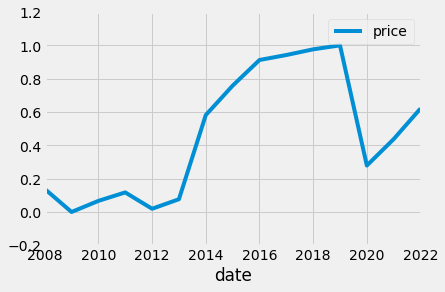

In [21]:
DAFY_nor.plot(grid=True)
plt.show()

Nearly positive trend.

In [22]:
DAFY_nor_diff = DAFY_nor.diff(1).dropna()
DAFY_nor_diff.head()

,price
date,
2009-01-01,-0.138512
2010-01-01,0.066530
2011-01-01,0.050895
2012-01-01,-0.098107
2013-01-01,0.057236


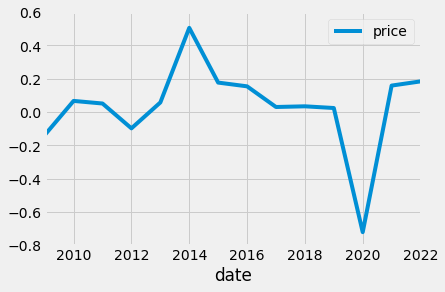

In [23]:
DAFY_nor_diff.plot(grid=True)
plt.show()

##### Checking Random Walk

In [24]:
RW_DAFY = adfuller(DAFY_nor_diff)
RW_DAFY[1] # print P-value. If p-value<5%, reject null hypothesis

0.00010520893072316454

##### Plot ACF and PACF

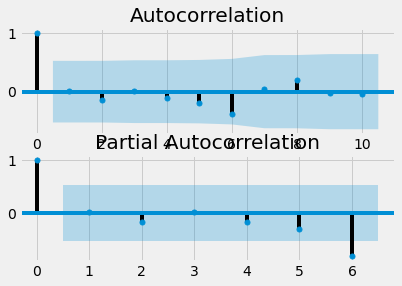

In [25]:
fig, axes=plt.subplots(2,1)
plot_acf(DAFY_nor_diff, lags=10, ax=axes[0])
plot_pacf(DAFY_nor_diff, lags=6, ax=axes[1])
plt.show()

##### Choose smallest AIC and BIC

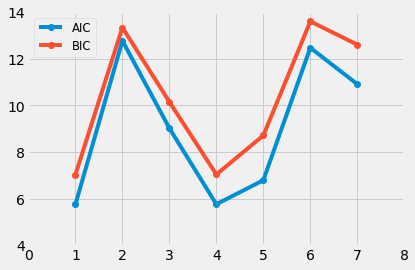

In [26]:
AIC, BIC = AIC_BIC_withOrderRange(DAFY_nor_diff, p=2, d=2, q=2)
# 0:(0,0,0), 1:(0,0,1), 2:(0,1,0), 3:(0,1,1), 4:(1,0,0), 5:(1,0,1), 6:(1,1,0), 7:(1,1,1)

In [27]:
AIC, BIC

(array([ 3.77623691,  5.75355812, 12.76921599,  9.01748535,  5.75915012,
         6.79103527, 12.46712562, 10.90779636]),
 array([ 4.41529423,  7.03167278, 13.33416535, 10.14738406,  7.03726478,
         8.70820726, 13.59702434, 12.60264444]))

We shouldn't choose the AIC or BIC with values `0.`

##### We will run 1:(0,0,1),  4:(1,0,0)

In [28]:
mod_orders = [
    (0,0,1),
    (1,0,0)
]

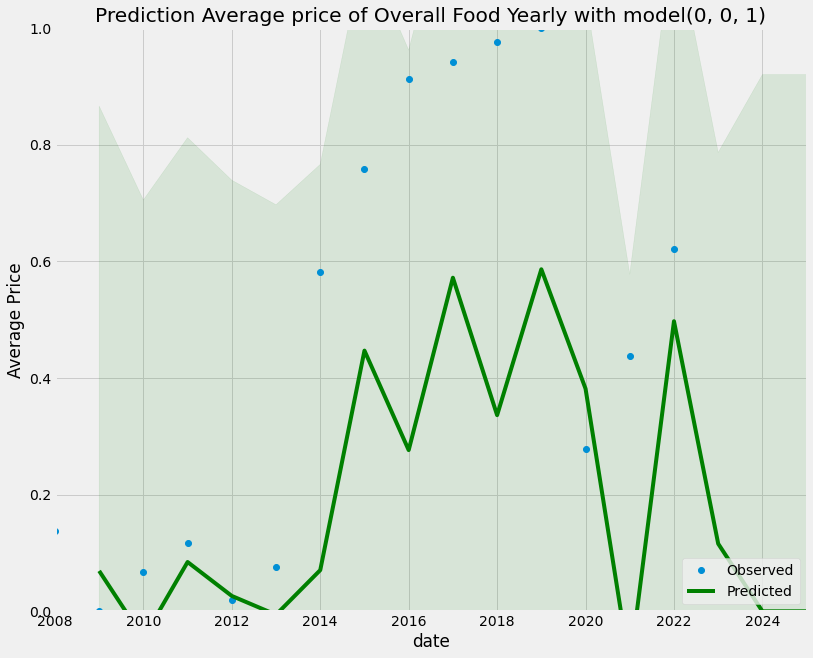

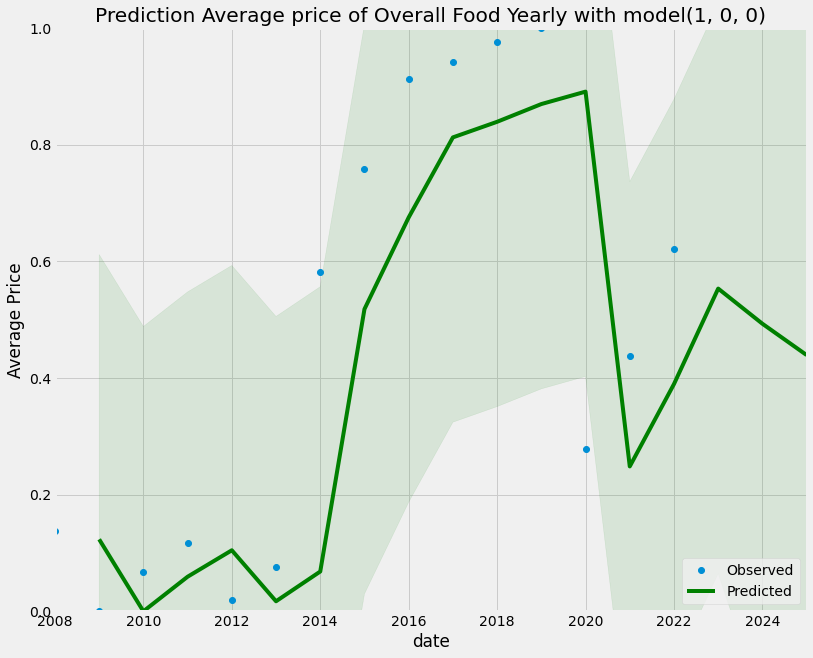

In [29]:
DAFY_models = []
for ind, order in enumerate(mod_orders): 
    model = Run_SARIMAX(DAFY_nor, mod_order=order, time_range=[[obv_st_date, obv_end_date], [pred_st_date, pred_end_date]], col='price', title='Prediction Average price of Overall Food Yearly with model'+str(order), xlabel='Year', ylabel='Average Price')
    DAFY_models.append(model)

In [30]:
DAFY_model = DAFY_models[1]

In [31]:
DAFY_pred_normalized = DAFY_model.predict(pred_st_date, pred_end_date)
DAFY_pred_normalized

2009-01-01    1.234223e-01
2010-01-01    2.329941e-18
2011-01-01    5.928186e-02
2012-01-01    1.046321e-01
2013-01-01    1.721277e-02
2014-01-01    6.821387e-02
2015-01-01    5.181392e-01
2016-01-01    6.753725e-01
2017-01-01    8.126000e-01
2018-01-01    8.393428e-01
2019-01-01    8.697490e-01
2020-01-01    8.910592e-01
2021-01-01    2.484107e-01
2022-01-01    3.896714e-01
2023-01-01    5.533472e-01
2024-01-01    4.930651e-01
2025-01-01    4.393502e-01
Freq: AS-JAN, dtype: float64

In [32]:
mask = (DAFY_nor.index>=pred_st_date) & (DAFY_nor.index<=pred_end_date)
DAFY_pred = DAFY_nor.loc[mask]
DAFY_pred

,price
date,
2009-01-01,0.000000
2010-01-01,0.066530
2011-01-01,0.117424
2012-01-01,0.019317
2013-01-01,0.076554
2014-01-01,0.581487
2015-01-01,0.757943
2016-01-01,0.911948
2017-01-01,0.941961


In [33]:
pred_date = DAFY_pred_normalized.index
pred_date = pred_date[:-1] # the last index doesn't need
pred_date

DatetimeIndex(['2009-01-01', '2010-01-01', '2011-01-01', '2012-01-01',
               '2013-01-01', '2014-01-01', '2015-01-01', '2016-01-01',
               '2017-01-01', '2018-01-01', '2019-01-01', '2020-01-01',
               '2021-01-01', '2022-01-01', '2023-01-01', '2024-01-01'],
              dtype='datetime64[ns]', freq='AS-JAN')

We need to un-normalized the predicted value to get actual price

In [34]:
# DAFY_pred_normalized['need'] = 0 # Expected 2D array, got 1D array instead
DAFY_pred_normalized_df = pd.DataFrame(DAFY_pred_normalized)
DAFY_pred_normalized_df = DAFY_pred_normalized_df[:-1] # the last index doesn't need
DAFY_pred_normalized_df

,0
2009-01-01,1.234223e-01
2010-01-01,2.329941e-18
2011-01-01,5.928186e-02
2012-01-01,1.046321e-01
2013-01-01,1.721277e-02
2014-01-01,6.821387e-02
2015-01-01,5.181392e-01
2016-01-01,6.753725e-01
2017-01-01,8.126000e-01
2018-01-01,8.393428e-01


In [35]:
DAFY_pred_act = scaler.inverse_transform(DAFY_pred_normalized_df)
DAFY_pred_act_df = pd.DataFrame(DAFY_pred_act)
DAFY_pred_act_df['date'] = pred_date
DAFY_pred_act_df.columns = ['Predicted Price', 'date']
DAFY_pred_act_df.set_index('date', inplace=True)
DAFY_pred_act_df.dropna()

,Predicted Price
date,
2009-01-01,981.258531
2010-01-01,805.337847
2011-01-01,889.835552
2012-01-01,954.475715
2013-01-01,829.872166
2014-01-01,902.566840
2015-01-01,1543.870322
2016-01-01,1767.983570
2017-01-01,1963.581607


In [36]:
mask = (DAFY.index>=pred_st_date) & (DAFY.index<=pred_end_date)
DAFY_Act = DAFY.loc[mask]
DAFY_Act

,price
date,
2009-01-01,805.337847
2010-01-01,900.166229
2011-01-01,972.709289
2012-01-01,832.871728
2013-01-01,914.454042
2014-01-01,1634.163191
2015-01-01,1885.676491
2016-01-01,2105.188314
2017-01-01,2147.966578


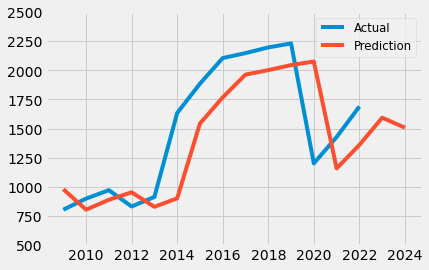

In [37]:
plt.plot(DAFY_Act, label="Actual")
plt.plot(DAFY_pred_act_df, label="Prediction")
plt.legend(loc='best',fontsize='small')
plt.show()

### Linear Regression

In [38]:
temp_df = DAFY_nor.copy()
temp_df.reset_index(inplace =True)
temp_df

,date,price
0,2008-01-01,0.138512
1,2009-01-01,0.000000
2,2010-01-01,0.066530
3,2011-01-01,0.117424
4,2012-01-01,0.019317
5,2013-01-01,0.076554
6,2014-01-01,0.581487
7,2015-01-01,0.757943
8,2016-01-01,0.911948
9,2017-01-01,0.941961


In [39]:
temp_df['time'] = temp_df['date'].apply(lambda x: x.value)
mask = np.random.rand(len(temp_df)) < 0.7
train = temp_df[mask]
test = temp_df[~mask]
train, test

(         date     price                 time
 0  2008-01-01  0.138512  1199145600000000000
 2  2010-01-01  0.066530  1262304000000000000
 3  2011-01-01  0.117424  1293840000000000000
 4  2012-01-01  0.019317  1325376000000000000
 5  2013-01-01  0.076554  1356998400000000000
 6  2014-01-01  0.581487  1388534400000000000
 7  2015-01-01  0.757943  1420070400000000000
 8  2016-01-01  0.911948  1451606400000000000
 9  2017-01-01  0.941961  1483228800000000000
 10 2018-01-01  0.976084  1514764800000000000
 11 2019-01-01  1.000000  1546300800000000000
 14 2022-01-01  0.620999  1640995200000000000,
          date     price                 time
 1  2009-01-01  0.000000  1230768000000000000
 12 2020-01-01  0.278781  1577836800000000000
 13 2021-01-01  0.437313  1609459200000000000)

In [40]:
X_train = train.time
X_train = X_train.values.reshape((-1,1))
y_train = train['price'].values
X_train[:10], y_train[:10]

(array([[1199145600000000000],
        [1262304000000000000],
        [1293840000000000000],
        [1325376000000000000],
        [1356998400000000000],
        [1388534400000000000],
        [1420070400000000000],
        [1451606400000000000],
        [1483228800000000000],
        [1514764800000000000]], dtype=int64),
 array([0.13851194, 0.06652965, 0.11742437, 0.01931721, 0.07655368,
        0.58148685, 0.75794342, 0.9119484 , 0.94196076, 0.97608439]))

In [41]:
X_test = test.time
X_test = X_test.values.reshape((-1,1))
y_test = test['price'].values
X_test[:10], y_test[:10]

(array([[1230768000000000000],
        [1577836800000000000],
        [1609459200000000000]], dtype=int64),
 array([0.        , 0.27878135, 0.4373126 ]))

In [42]:
X = np.concatenate((X_train, X_test), axis = 0)
y = np.concatenate((y_train, y_test), axis = 0)

In [43]:
DAFY_nor_linreg = LinearRegression().fit(X_train, y_train)

In [44]:
print('linear model coeff or slope (w): {}'.format(DAFY_nor_linreg.coef_))
print('linear model intercept (b): {:.3f}'.format(DAFY_nor_linreg.intercept_))
print('R-squared score (training): {:.3f}'.format(DAFY_nor_linreg.score(X_train, y_train)))
print('R-squared score (test): {:.3f}'.format(DAFY_nor_linreg.score(X_test, y_test)))

linear model coeff or slope (w): [2.46833347e-18]
linear model intercept (b): -2.955
R-squared score (training): 0.610
R-squared score (test): -6.951


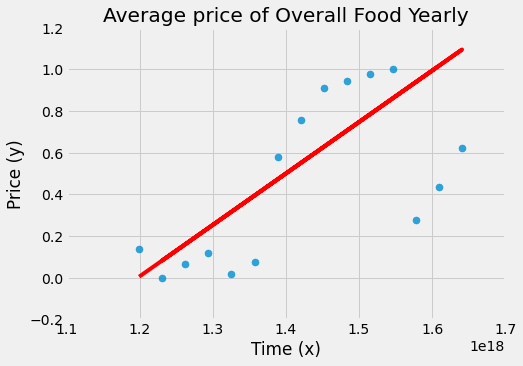

In [45]:
plt.figure(figsize=(7,5))
plt.scatter(X, y, marker= 'o', s=50, alpha=0.8)
plt.plot(X, DAFY_nor_linreg.coef_ * X + DAFY_nor_linreg.intercept_, 'r-')
plt.title('Average price of Overall Food Yearly')
plt.xlabel('Time (x)')
plt.ylabel('Price (y)')
plt.show()

In [46]:
DAFY_nor_linear_predict = pd.DataFrame(pd.date_range(start=pred_st_date,end=pred_end_date, freq='YS').to_pydatetime().tolist(), columns=['date'])
DAFY_nor_linear_predict['time'] = DAFY_nor_linear_predict['date'].apply(lambda x: x.value)
DAFY_nor_linear_predict

,date,time
0,2009-01-01,1230768000000000000
1,2010-01-01,1262304000000000000
2,2011-01-01,1293840000000000000
3,2012-01-01,1325376000000000000
4,2013-01-01,1356998400000000000
5,2014-01-01,1388534400000000000
6,2015-01-01,1420070400000000000
7,2016-01-01,1451606400000000000
8,2017-01-01,1483228800000000000
9,2018-01-01,1514764800000000000


In [47]:
time_predict = np.array(DAFY_nor_linear_predict['time']).reshape((-1, 1))
DAFY_nor_linear_predict['price'] = DAFY_nor_linreg.predict(time_predict)
DAFY_nor_linear_predict

,date,time,price
0,2009-01-01,1230768000000000000,0.082569
1,2010-01-01,1262304000000000000,0.160410
2,2011-01-01,1293840000000000000,0.238252
3,2012-01-01,1325376000000000000,0.316093
4,2013-01-01,1356998400000000000,0.394148
5,2014-01-01,1388534400000000000,0.471989
6,2015-01-01,1420070400000000000,0.549831
7,2016-01-01,1451606400000000000,0.627672
8,2017-01-01,1483228800000000000,0.705727
9,2018-01-01,1514764800000000000,0.783568


In [48]:
DAFY_linear_normalized_predict = DAFY_nor_linear_predict.copy()
DAFY_linear_normalized_predict = DAFY_linear_normalized_predict[['date', 'price']]
DAFY_linear_normalized_predict.set_index('date', inplace=True)
DAFY_linear_normalized_predict

,price
date,
2009-01-01,0.082569
2010-01-01,0.160410
2011-01-01,0.238252
2012-01-01,0.316093
2013-01-01,0.394148
2014-01-01,0.471989
2015-01-01,0.549831
2016-01-01,0.627672
2017-01-01,0.705727


##### Unnormalized the data

In [49]:
DAFY_pred_act_linear = scaler.inverse_transform(DAFY_linear_normalized_predict)
DAFY_pred_act_linear_df = pd.DataFrame(DAFY_pred_act_linear)
DAFY_pred_act_linear_df['date'] = DAFY_nor_linear_predict['date']
DAFY_pred_act_linear_df.columns = ['Predicted Price (KG)', 'date']
DAFY_pred_act_linear_df.set_index('date', inplace=True)
DAFY_pred_act_linear_df

,Predicted Price (KG)
date,
2009-01-01,923.028175
2010-01-01,1033.979774
2011-01-01,1144.931373
2012-01-01,1255.882972
2013-01-01,1367.138548
2014-01-01,1478.090147
2015-01-01,1589.041746
2016-01-01,1699.993345
2017-01-01,1811.248921
